# 🌏 MosAIG Studio v2 — When Cultures Meet (Resumable Paper Implementation + Real-World App)

**Paper:** *When Cultures Meet: Multicultural Text-to-Image Generation* (Bhalerao, Yalamarty, Trinh, Ignat — Findings of ACL 2026)

| Paper ka hissa | Is notebook mein |
|---|---|
| Task: person (culture A) + landmark (culture B) | 5 countries × 3 ages × 2 genders × 25 landmarks × 5 languages (Table 1) |
| **MosAIG** agents (Moderator, Country, Landmark, Age-Gender, Summarizer; 2 rounds; ≤48 words / ≤77 tokens) | Figure 9 ke prompts, Groq par Llama-3.1-8B |
| Simple vs Multi-agent | dono, same seed |
| Models | AltDiffusion-m18, FLUX.1 Lite (bada GPU), SDXL (fast) |
| 5 metrics | Alignment (CLIP), Quality (IS), Aesthetics (SigLIP v2.5), Knowledge (landmark swap), Fairness (demographic substitution) |
| Plots | Figure 3/4/6/7 style |
| Human evaluation | blinded Likert CSV + weighted Cohen's κ + error tags |
| **Real-world app** | Gradio studio: prompt → multi-agent caption → best-of-N → CLIP+knowledge+aesthetic ranking → best image |

## 🔁 RESUME KAISE KAAM KARTA HAI (ye v2 ki main feature hai)
- **Sab kuch Google Drive mein save hota hai** (`MyDrive/MosAIG_Studio`): captions, har image, har score, human-eval template, studio outputs.
- Har image **atomic** save hoti hai (pehle temp file, phir rename) → beech mein crash hone par half-written image nahi bachti.
- Har score **turant** `scores.jsonl` mein append hota hai. Captions har ek ke baad cache hote hain. LLM fail hone par kharab fallback caption cache **nahi** hota.
- Dobara run karne par jo ban chuka hai wo **skip** hota hai; sirf bacha hua kaam chalta hai.
- **GPU quota khatam / disconnect / crash hone par:**
  1. Naya runtime (GPU) lo → **Cell 1 (install)** → Runtime → **Restart session**
  2. **Cell 2 se Cell 7 tak** run karo (setup, keys, definitions) — ye fast hain
  3. Jo benchmark cell adhoora tha (8a / 8b) **bas dobara run karo** — wahin se aage badhega.
  4. `show_progress()` se dekh sakte ho kitna ho chuka hai.
- Models (HF weights, ~10 GB) Drive par nahi rakhe (Drive free space kam hoti hai); wo naye runtime par dobara download hote hain (~2–5 min).

## Seedha steps
1. Runtime → Change runtime type → **T4 GPU**
2. Cells upar se neeche. Heavy cells (8a, 8b, 10) tabhi chalao jab chahiye.
3. Groq key (free): console.groq.com. Colab **Secrets** (🔑 icon) mein `GROQ_API_KEY` save kar do to har baar type nahi karni padegi.

## Honesty notes
- Paper ka CrewAI + local LLaMA setup yahan Groq-hosted Llama + seedha agent loop se replicate hai. Exact paper numbers ki guarantee nahi.
- Paper ke 9,000 images T4 par ghanton lagenge → sample size (`n_cases`) configurable hai; badhane par purana kaam reuse hota hai.
- **FLUX.1 Lite 8B free T4 par nahi chalega** (VRAM/RAM). AltDiffusion ya SDXL use karo.
- CLIP/IS/aesthetic **proxy** scores hain; cultural correctness prove nahi karte → human evaluation cell hai.
- Notebook ka logic maine offline test kiya (resume, caption cache, scoring), par GPU/model-download/Groq API ka live run aapke Colab par hi verify hota hai.

## 1. Install pinned packages

PyTorch ko touch nahi karta. Ke baad **Runtime → Restart session** karo, phir **Cell 2** se aage chalo. (Naye runtime par bhi yahi order.)

In [1]:
%pip uninstall -y -q torchao
%pip install -q "diffusers==0.35.1" "transformers==4.55.4" "accelerate==1.10.1" "huggingface_hub==0.34.4" "safetensors>=0.4.5" "sentencepiece>=0.2.0" "protobuf" "groq" "gradio==5.49.1" "pandas" "openpyxl" "scikit-learn" "matplotlib" "tqdm" "psutil"
print("Install complete. Ab Runtime -> Restart session karo, phir Cell 2 run karo.")

Install complete. Ab Runtime -> Restart session karo, phir Cell 2 run karo.


## 2. Setup: Drive, paths, GPU check, checkpoint utilities (restart ke baad yahin se)

In [2]:
import os, sys, gc, json, re, time, random, shutil, zipfile, hashlib, subprocess
from pathlib import Path
import numpy as np, pandas as pd, torch, psutil
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

# ---- Persistent storage (Google Drive) so work survives disconnects ----
USE_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    _probe = Path("/content/drive/MyDrive/.mosaig_write_test"); _probe.write_text("ok"); _probe.unlink()
    USE_DRIVE = True
except Exception as e:
    print("Google Drive mount nahi hua ->", str(e)[:150])
PROJECT_DIR = Path("/content/drive/MyDrive/MosAIG_Studio") if USE_DRIVE else Path("/content/MosAIG_Studio")
RESULTS_DIR = PROJECT_DIR / "results"
STUDIO_DIR, BENCH_DIR, HUMAN_DIR = RESULTS_DIR / "studio", RESULTS_DIR / "benchmark", RESULTS_DIR / "human_eval"
CACHE_FILE = PROJECT_DIR / "caption_cache.json"
for d in [PROJECT_DIR, RESULTS_DIR, STUDIO_DIR, BENCH_DIR, HUMAN_DIR]: d.mkdir(parents=True, exist_ok=True)
print("Storage:", PROJECT_DIR, "(Google Drive - resume safe)" if USE_DRIVE else
      "(LOCAL - disconnect par SAB DELETE ho jayega! Drive allow karke Cell 2 dobara chalao)")

SEED = 42
LLM_MODELS = ["llama-3.1-8b-instant", "llama-3.3-70b-versatile", "openai/gpt-oss-20b"]  # paper: LLaMA-3.1-8B
NEGATIVE_PROMPT = ("blurry, low resolution, distorted anatomy, malformed hands, extra fingers, "
                   "text, watermark, logo, duplicated person, deformed face, visual artifacts")
ALLOW_CPU = False   # True mat karo: CPU par ek image ~4 minute leti hai

# ---- Checkpoint utilities ----
def _atomic_write_text(path, text):
    path = Path(path); tmp = Path(str(path) + ".tmp"); tmp.write_text(text, encoding="utf-8"); os.replace(tmp, path)

def _atomic_save_image(img, path):
    path = Path(path); tmp = path.with_name(path.stem + ".tmp.png"); img.save(tmp); os.replace(tmp, path)

def _valid_image(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except Exception:
        return False

def append_jsonl(path, obj):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(obj, ensure_ascii=False) + "\n"); f.flush(); os.fsync(f.fileno())

def load_jsonl(path):
    """key -> merged dict (later lines update earlier ones); tolerant to a half-written last line."""
    out = {}
    if not Path(path).exists(): return out
    for line in open(path, encoding="utf-8", errors="ignore"):
        line = line.strip()
        if not line: continue
        try: o = json.loads(line)
        except Exception: continue
        if "key" in o: out.setdefault(o["key"], {}).update({k: v for k, v in o.items() if k != "key"})
    return out

def _load_cache():
    try: return json.loads(CACHE_FILE.read_text(encoding="utf-8"))
    except FileNotFoundError: return {}
    except Exception:
        try: shutil.copy2(CACHE_FILE, str(CACHE_FILE) + ".corrupt")
        except Exception: pass
        return {}
def _save_cache(c): _atomic_write_text(CACHE_FILE, json.dumps(c, ensure_ascii=False, indent=1))

def _clean(v):
    return None if (isinstance(v, float) and np.isnan(v)) else v

def show_progress():
    """Kitna kaam ho chuka hai (captions, images, scores) - Drive se seedha."""
    print("Storage:", PROJECT_DIR)
    c = _load_cache()
    print("Cached captions:", sum(1 for k in c if k.count("|") == 4), "| translations:", sum(1 for k in c if k.count("|") == 5))
    for d in sorted(BENCH_DIR.glob("*")):
        if d.is_dir():
            imgs = len([p for p in d.glob("*.png") if ".tmp" not in p.name])
            sc = load_jsonl(d / ("fair_scores.jsonl" if d.name.startswith("fairness") else "scores.jsonl"))
            aes = sum(1 for v in sc.values() if v.get("aesthetic") is not None)
            print(f" - {d.name}: images={imgs}, scored={len(sc)}, aesthetic={aes}")
    print("Studio runs:", len([p for p in STUDIO_DIR.glob('*') if p.is_dir()]))

# ---- Hardware ----
import diffusers, transformers
print("torch", torch.__version__, "| diffusers", diffusers.__version__, "| transformers", transformers.__version__)
HAS_CUDA = torch.cuda.is_available()
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3 if HAS_CUDA else 0
RAM_GB = psutil.virtual_memory().total / 1024**3
print("GPU:", torch.cuda.get_device_name(0) if HAS_CUDA else "NONE", "| VRAM GB:", round(VRAM_GB, 1), "| RAM GB:", round(RAM_GB, 1))
if not HAS_CUDA:
    print("\n!!! GPU nahi mila (quota khatam ya CPU runtime). Image generation block rahegi. "
          "Runtime -> Change runtime type -> T4 GPU; mile na to baad mein dobara try karo. Saara purana kaam Drive mein safe hai.")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
show_progress()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Storage: /content/drive/MyDrive/MosAIG_Studio (Google Drive - resume safe)
torch 2.11.0+cu130 | diffusers 0.35.1 | transformers 4.55.4
GPU: Tesla T4 | VRAM GB: 14.6 | RAM GB: 12.7
Storage: /content/drive/MyDrive/MosAIG_Studio
Cached captions: 54 | translations: 0
 - AltDiffusion-m18_fast_s42: images=24, scored=24, aesthetic=24
 - fairness_AltDiffusion-m18_fast_s42: images=32, scored=32, aesthetic=0
Studio runs: 2


## 3. API keys

Pehle Colab **Secrets** (`GROQ_API_KEY`, `HF_TOKEN`) check hota hai, nahi mile to hidden prompt. Key kisi ke saath share mat karo.

In [3]:
 from getpass import getpass
try:
    from google.colab import userdata
    for _k in ("GROQ_API_KEY", "HF_TOKEN"):
        if not os.environ.get(_k):
            try: _v = userdata.get(_k)
            except Exception: _v = None
            if _v: os.environ[_k] = _v
except Exception:
    pass
if not os.environ.get("GROQ_API_KEY"):
    try: os.environ["GROQ_API_KEY"] = getpass("Groq API key (Enter dabao to skip): ").strip()
    except Exception: pass
if os.environ.get("HF_TOKEN"):
    from huggingface_hub import login
    login(token=os.environ["HF_TOKEN"], add_to_git_credential=False); print("Hugging Face login done.")

_LLM = {"client": None, "model": None}

def init_llm():
    key = os.environ.get("GROQ_API_KEY", "").strip()
    if not key:
        print("Groq key nahi mili -> multi-agent OFF (template captions)."); return False
    from groq import Groq
    c = Groq(api_key=key)
    for m in LLM_MODELS:
        try:
            c.chat.completions.create(model=m, messages=[{"role": "user", "content": "Reply with OK"}], max_tokens=20)
            _LLM.update(client=c, model=m); print("LLM ready:", m); return True
        except Exception as e:
            print("LLM model failed:", m, "->", str(e)[:140])
    print("Koi Groq model nahi chala. Key check karo."); return False

def ask_llm(system, user, max_tokens=200, temperature=0.7):
    c = _LLM["client"]
    if c is None: return None
    if "gpt-oss" in (_LLM["model"] or ""): max_tokens = max(max_tokens, 900)
    for attempt in range(5):
        try:
            r = c.chat.completions.create(model=_LLM["model"], temperature=temperature, max_tokens=max_tokens,
                    messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
            txt = (r.choices[0].message.content or "").strip()
            if txt: return txt
        except Exception as e:
            msg = str(e).lower()
            if "429" in msg or "rate" in msg: time.sleep(8 * (attempt + 1)); continue
            if attempt == 4: print("LLM call failed:", str(e)[:160]); return None
            time.sleep(2)
    return None

LLM_OK = init_llm()

Groq API key (Enter dabao to skip): ··········
LLM model failed: llama-3.1-8b-instant -> Error code: 404 - {'error': {'message': 'The model `llama-3.1-8b-instant` does not exist or you do not have access to it.', 'type': 'invalid
LLM model failed: llama-3.3-70b-versatile -> Error code: 404 - {'error': {'message': 'The model `llama-3.3-70b-versatile` does not exist or you do not have access to it.', 'type': 'inva
LLM ready: openai/gpt-oss-20b


## 4. Dataset definitions (paper Table 1) + Simple captions

In [4]:
COUNTRIES = {  # country -> (nationality adjective, 5 landmarks)  [Table 1]
    "Germany": ("German",     ["Cologne Cathedral", "Reichstag Building", "Neuschwanstein Castle", "Brandenburg Gate", "Holocaust Memorial"]),
    "India":   ("Indian",     ["Taj Mahal", "Lotus Temple", "Gateway of India", "India Gate", "Charminar"]),
    "Spain":   ("Spanish",    ["Sagrada Familia", "Alhambra", "Guggenheim Museum", "Roman Theater of Cartagena", "Royal Palace of Madrid"]),
    "U.S.":    ("American",   ["White House", "Statue of Liberty", "Mount Rushmore", "Golden Gate Bridge", "Lincoln Memorial"]),
    "Vietnam": ("Vietnamese", ["Meridian Gate of Huế", "Independence Palace", "One Pillar Pagoda", "Ho Chi Minh Mausoleum", "Thien Mu Pagoda"]),
}
NAT2COUNTRY = {v[0]: k for k, v in COUNTRIES.items()}
NATIONALITIES = list(NAT2COUNTRY)
LANDMARK2COUNTRY = {lm: c for c, (_, lms) in COUNTRIES.items() for lm in lms}
LANDMARKS = list(LANDMARK2COUNTRY)
AGES = ["child", "adult", "elder"]
GENDERS = ["female", "male"]
LANGUAGES = ["English", "German", "Hindi", "Spanish", "Vietnamese"]

AG_WORDS = {("child","female"):("12-year-old","girl"), ("child","male"):("10-year-old","boy"),
            ("adult","female"):("35-year-old","woman"), ("adult","male"):("35-year-old","man"),
            ("elder","female"):("elderly","woman"),     ("elder","male"):("elderly","man")}
def ag_words(age, gender):
    if (age, gender) in AG_WORDS: return AG_WORDS[(age, gender)]
    return {"child": ("10-year-old","child"), "adult": ("35-year-old","person"), "elder": ("elderly","person")}.get(age, ("35-year-old","person"))
def age_gender_combined(age, gender):
    p, n = ag_words(age, gender); return f"{p} {n}"
SIMPLE_NOUN = {("child","female"):"girl", ("child","male"):"boy", ("adult","female"):"woman", ("adult","male"):"man",
               ("elder","female"):"old woman", ("elder","male"):"old man"}
def simple_caption(nationality, age, gender, landmark):
    noun = SIMPLE_NOUN.get((age, gender), {"child":"child","adult":"person","elder":"old person"}.get(age, "person"))
    return f"A {nationality} {noun} wearing traditional attire, standing in front of the {landmark}."

def build_prompt_grid():
    rows = []
    for nat in NATIONALITIES:
        for age in AGES:
            for gen in GENDERS:
                for lm in LANDMARKS:
                    rows.append(dict(nationality=nat, person_country=NAT2COUNTRY[nat], age=age, gender=gen,
                                     landmark=lm, landmark_country=LANDMARK2COUNTRY[lm]))
    return pd.DataFrame(rows)
GRID = build_prompt_grid()
print("Base prompt grid:", len(GRID), "| x languages =", len(GRID) * len(LANGUAGES))
print(simple_caption("Vietnamese", "child", "female", "Golden Gate Bridge"))

Base prompt grid: 750 | x languages = 3750
A Vietnamese girl wearing traditional attire, standing in front of the Golden Gate Bridge.


## 5. MosAIG — Multi-Agent caption framework (paper Section 3 + Figure 9)

Moderator = predefined function. Country / Landmark / Age-Gender agents: **Round 1** (<25 words) → **Round 2** (ek doosre ke jawab dekhkar enhance) → **Summarizer** (<48 words, <77 CLIP tokens).
Agar LLM call fail ho jaye to fallback caption bana kar **cache nahi** kiya jata (benchmark rukega aur dobara run karne par wahin se chalega).

In [5]:
_TOK = {"t": None}
def clip_token_len(text):
    try:
        if _TOK["t"] is None:
            from transformers import CLIPTokenizer
            _TOK["t"] = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
        return len(_TOK["t"](text, add_special_tokens=False).input_ids)
    except Exception:
        return int(len(text.split()) * 1.6)

def fit_tokens(text, landmark, limit=74):
    """Drop trailing detail phrases until the caption fits CLIP's 77-token window (landmark phrase is kept)."""
    parts = [p.strip() for p in re.split(r",\s*", text.rstrip(". "))]
    while len(parts) > 1 and clip_token_len(", ".join(parts) + ".") > limit:
        for idx in range(len(parts) - 1, 0, -1):
            if landmark.lower() not in parts[idx].lower(): parts.pop(idx); break
        else: break
    out = ", ".join(parts).rstrip(".") + "."
    words = out.split()
    while clip_token_len(out) > limit and len(words) > 10:
        words.pop(); out = " ".join(words).rstrip(",;:") + "."
    return out

def finalize_caption(text, nationality, landmark, max_words=48):
    t = (text or "").strip().split("\n")[0].strip().strip('"').strip("'").strip()
    t = re.sub(r"^(final prompt|prompt|caption)\s*:\s*", "", t, flags=re.I)
    words = t.split()
    if len(words) > max_words: t = " ".join(words[:max_words]).rstrip(",;:") + "."
    if landmark.lower() not in t.lower(): t = t.rstrip(".") + f", in front of the {landmark}."
    return fit_tokens(t, landmark)

def fallback_multi_caption(nationality, age, gender, landmark, extra=""):
    p, n = ag_words(age, gender)
    t = (f"A {p} {nationality} {n} wearing traditional attire, standing in front of the {landmark}, "
         f"its architecture clearly visible in the background, natural daylight, realistic photograph")
    if extra: t += f", {extra}"
    return finalize_caption(t, nationality, landmark)

def is_fallback(log):
    return any("fallback" in a.lower() for a, _ in log)

def mosaig_caption(nationality, age, gender, landmark, extra="", rounds=2):
    """Returns (final_english_caption, agent_log list[(agent, text)])."""
    country = NAT2COUNTRY[nationality]; ag = age_gender_combined(age, gender); log = []
    log.append(("Moderator", f"nationality={nationality} ({country}), age-gender={ag}, landmark={landmark} -> tasks assigned to Country/Landmark/Age-Gender agents"))
    if _LLM["client"] is None:
        cap = fallback_multi_caption(nationality, age, gender, landmark, extra)
        log.append(("Summarizer (template fallback, no LLM)", cap)); return cap, log

    sys_c = f"You are a {nationality} person from {country} who knows the culture of this country well."
    sys_l = f"You are a person who has visited {landmark} many times and know this landmark well."
    sys_a = f"You are a {ag} and can describe traits of this person well."
    c = ask_llm(sys_c, f"Provide a visual description of culturally appropriate traditional clothing, accessories, and colors, for the {nationality} person. Focus on specific materials, key cultural patterns, and symbolic colors. Your response must be under 25 words.", 80)
    l = ask_llm(sys_l, "Provide a visual description of its architectural features, colors, and environmental details. Your response must be under 25 words.", 80)
    a = ask_llm(sys_a, "Provide a visual description of attire, accessories, and physical details. Focus on skin, body, hair texture, and accessories. Your response must be under 25 words.", 80)
    log += [("Country Agent R1", c), ("Landmark Agent R1", l), ("Age-Gender Agent R1", a)]
    if not (c and l and a):
        cap = fallback_multi_caption(nationality, age, gender, landmark, extra)
        log.append(("Summarizer (fallback: an agent call failed)", cap)); return cap, log
    for r in range(2, rounds + 1):
        c2 = ask_llm(sys_c, f"Your earlier description: {c}\nLandmark Agent says: {l}\nEnhance the persona description by addressing: 'How would a person's clothing harmonize with the colors of {landmark}?'. Ensure cultural significance is highlighted. Under 25 words.", 90)
        l2 = ask_llm(sys_l, f"Your earlier description: {l}\nCountry Agent says the attire is: {c}\nEnhance the place description by addressing: 'What visual elements of {landmark} would complement the persona's attire?'. Limit to under 25 words.", 80)
        a2 = ask_llm(sys_a, f"Your earlier description: {a}\nCountry Agent says the attire is: {c}\nEnhance the age-gender description by addressing: 'What attire adjustments could reflect age-appropriate traits for a {nationality} {ag}?'. Ensure specific details on attire and physical traits. Under 25 words.", 90)
        c, l, a = c2 or c, l2 or l, a2 or a
        log += [(f"Country Agent R{r}", c), (f"Landmark Agent R{r}", l), (f"Age-Gender Agent R{r}", a)]
    ctx = f"Country Agent: {c}\nLandmark Agent: {l}\nAge-Gender Agent: {a}\n" + (f"Extra user details to keep: {extra}\n" if extra else "")
    s = ask_llm("You excel at crafting concise visual prompts.",
                ctx + f"Give a final prompt in a single line under 48 words and under 77 tokens strictly. Ensure the words {nationality} and {ag} of the person and other descriptions with the {landmark} background are mentioned explicitly in the final prompt. Output only the prompt.", 140, 0.5)
    if not s:
        cap = fallback_multi_caption(nationality, age, gender, landmark, extra); log.append(("Summarizer (fallback: call failed)", cap))
    else:
        cap = finalize_caption(s, nationality, landmark); log.append(("Summarizer Agent", cap))
    return cap, log

def translate_text(text, language):
    if language == "English" or not text: return text
    out = ask_llm("You are a professional translator.", f"Translate the following text into {language}. Output only the translation.\n\n{text}", 400, 0.2)
    return (out or text).strip()

def to_english(text, language):
    if language == "English" or not text: return text
    out = ask_llm("You are a professional translator.", f"Translate the following {language} text into English. Output only the translation.\n\n{text}", 400, 0.2)
    return (out or text).strip()

_cap, _log = mosaig_caption("Vietnamese", "child", "female", "Golden Gate Bridge")
for who, txt in _log: print(f"[{who}] {txt}")
print("\nSIMPLE :", simple_caption("Vietnamese", "child", "female", "Golden Gate Bridge"))
print("MULTI  :", _cap, f"({clip_token_len(_cap)} CLIP tokens)")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

[Moderator] nationality=Vietnamese (Vietnam), age-gender=12-year-old girl, landmark=Golden Gate Bridge -> tasks assigned to Country/Landmark/Age-Gender agents
[Country Agent R1] Áo dài silk, brocade, embroidered lotus, dragon; gold brooch, lacquered fan; vermilion, jade green, gold accents.
[Landmark Agent R1] Twin towers, Art Deco arches, International Orange paint, steel cable suspension, fog‑shrouded San Francisco Bay, Pacific breezes, sunset hues.
[Age-Gender Agent R1] Bright red sneakers, denim jacket, freckles across her cheeks, curly chestnut hair, silver hoop earring, confident smile.
[Country Agent R2] Áo dài lụa xanh ngọc, hoa lotus cam, ruy băng vàng, hòa quyện với màu cam rực Cầu Vàng, biểu tượng hòa nhập hoá.
[Landmark Agent R2] International Orange clings to vermilion, gold‑accented cables echo brocade, jade green water mirrors lotus, Art Deco arches echo embroidered dragon, sunset hues warm lacquered fan.
[Age-Gender Agent R2] Short pastel áo dài with lotus, vermilion ri

## 6. Image generation models (paper Section 3.2)

| Model | Paper setting (`preset="paper"`) | Needs |
|---|---|---|
| **AltDiffusion-m18** (multilingual) | 768px, 110 steps, guidance 11, seed 11000 | T4 OK |
| **FLUX.1 Lite 8B** (English) | 768px, 30 steps, guidance 4, seed 11 | ≥24 GB VRAM & ≥25 GB RAM |
| **SDXL base** (English, fast) | 768px, 30 steps | T4 OK |

`preset="fast"` = kam steps/512px. Agar GPU nahi hai to ye cell image generation **rok deta hai** (CPU par ek image ~4 min lagti hai) — saara purana kaam safe rehta hai.

In [6]:
MODELS = {
    "AltDiffusion-m18": dict(kind="alt",  repo="BAAI/AltDiffusion-m18", multilingual=True,
        paper=dict(steps=110, guidance=11.0, size=768, seed=11000), fast=dict(steps=30, guidance=8.0, size=512, seed=11000)),
    "FLUX.1-lite-8B":   dict(kind="flux", repo="Freepik/flux.1-lite-8B-alpha", multilingual=False,
        paper=dict(steps=30, guidance=4.0, size=768, seed=11), fast=dict(steps=20, guidance=3.5, size=512, seed=11)),
    "SDXL-base":        dict(kind="sdxl", repo="stabilityai/stable-diffusion-xl-base-1.0", multilingual=False,
        paper=dict(steps=30, guidance=6.5, size=768, seed=11), fast=dict(steps=20, guidance=6.5, size=512, seed=11)),
}
_ACTIVE = {"name": None, "pipe": None}
_CLIP = {"model": None, "proc": None}
_AES = {"model": None, "pre": None}

def _free():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def unload_pipeline():
    if _ACTIVE["pipe"] is not None:
        try: _ACTIVE["pipe"].to("cpu")
        except Exception: pass
    _ACTIVE["pipe"] = None; _ACTIVE["name"] = None; _free()

def unload_evaluators():
    _CLIP["model"] = None; _CLIP["proc"] = None; _AES["model"] = None; _AES["pre"] = None; _free()

def _load_alt_pipeline(repo, dt):
    """AltDiffusion's model_index.json points to a custom module that diffusers>=0.3x does not resolve.
    We download the repo (resumable), blank that entry, and pass the text encoder in explicitly."""
    from huggingface_hub import snapshot_download
    import importlib
    local = snapshot_download(repo, local_dir="/content/AltDiffusion-m18",
                              ignore_patterns=["*.ckpt", "*.msgpack", "*.onnx", "*.h5", "*.ot", "*.png", "*.jpg", "*.SVG", "*.svg"])
    mi_path = Path(local) / "model_index.json"; mi = json.loads(mi_path.read_text())
    te_entry = mi.get("text_encoder")
    if isinstance(te_entry, list) and te_entry and te_entry[0] not in (None, "transformers"):
        mi["text_encoder"] = [None, None]; mi_path.write_text(json.dumps(mi, indent=2))
    R = None
    for mod in ("diffusers.pipelines.deprecated.alt_diffusion.modeling_roberta_series",
                "diffusers.pipelines.alt_diffusion.modeling_roberta_series"):
        try: R = importlib.import_module(mod).RobertaSeriesModelWithTransformation; break
        except Exception: pass
    if R is None: raise RuntimeError("AltDiffusion text-encoder class diffusers mein nahi mila. BENCH_MODEL='SDXL-base' use karo.")
    te = R.from_pretrained(local, subfolder="text_encoder", torch_dtype=dt)
    P = None
    for mod in ("diffusers", "diffusers.pipelines.deprecated.alt_diffusion", "diffusers.pipelines.alt_diffusion"):
        try: P = getattr(importlib.import_module(mod), "AltDiffusionPipeline"); break
        except Exception: pass
    if P is None: raise RuntimeError("AltDiffusionPipeline import nahi hua. BENCH_MODEL='SDXL-base' use karo.")
    return P.from_pretrained(local, text_encoder=te, torch_dtype=dt, safety_checker=None, requires_safety_checker=False, low_cpu_mem_usage=True)

def load_pipeline(name):
    if _ACTIVE["name"] == name and _ACTIVE["pipe"] is not None: return _ACTIVE["pipe"]
    if not HAS_CUDA and not ALLOW_CPU:
        raise RuntimeError("GPU available nahi hai (quota khatam / CPU runtime). Progress Drive mein safe hai. "
                           "Runtime -> Change runtime type -> T4 GPU, Cell 1 (install) + restart + Cell 2..7 chalao, phir yehi cell dobara run karo.")
    unload_pipeline(); unload_evaluators()
    spec = MODELS[name]
    if spec["kind"] == "flux" and (VRAM_GB < 22 or RAM_GB < 24):
        raise RuntimeError(f"FLUX.1 Lite 8B ko ~24GB VRAM aur ~25GB RAM chahiye (aapke paas VRAM {VRAM_GB:.0f}GB, RAM {RAM_GB:.0f}GB). "
                           "T4 par 'AltDiffusion-m18' ya 'SDXL-base' use karo.")
    dt = torch.float16 if HAS_CUDA else torch.float32
    print(f"Loading {name} ... (pehli baar download mein kuch minute lag sakte hain)")
    if spec["kind"] == "alt":
        pipe = _load_alt_pipeline(spec["repo"], dt)
    elif spec["kind"] == "sdxl":
        from diffusers import StableDiffusionXLPipeline
        pipe = StableDiffusionXLPipeline.from_pretrained(spec["repo"], torch_dtype=dt, use_safetensors=True, variant="fp16" if HAS_CUDA else None, low_cpu_mem_usage=True)
    else:
        from diffusers import FluxPipeline
        bf = HAS_CUDA and torch.cuda.is_bf16_supported()
        pipe = FluxPipeline.from_pretrained(spec["repo"], torch_dtype=torch.bfloat16 if bf else dt, low_cpu_mem_usage=True)
    for fn in ("enable_vae_slicing", "enable_vae_tiling"):
        try: getattr(pipe, fn)()
        except Exception: pass
    if HAS_CUDA:
        if spec["kind"] != "flux" and VRAM_GB >= 14:       # T4 (15GB): keep whole model on GPU = much faster
            try: pipe.to("cuda")
            except Exception: pipe.enable_model_cpu_offload()
        else:
            try: pipe.enable_model_cpu_offload()
            except Exception: pipe.enable_sequential_cpu_offload()
    else:
        pipe.to("cpu")
    pipe.set_progress_bar_config(disable=True)
    _ACTIVE["name"], _ACTIVE["pipe"] = name, pipe
    return pipe

def generate_image(model, prompt, preset="fast", seed=None, negative=NEGATIVE_PROMPT, size=None, steps=None, guidance=None):
    spec = MODELS[model]; cfg = dict(spec[preset])
    if size: cfg["size"] = int(size)
    if steps: cfg["steps"] = int(steps)
    if guidance: cfg["guidance"] = float(guidance)
    seed = int(cfg["seed"] if seed is None else seed)
    pipe = load_pipeline(model)
    g = torch.Generator("cpu").manual_seed(seed)
    kw = dict(prompt=prompt, height=cfg["size"], width=cfg["size"], num_inference_steps=cfg["steps"], guidance_scale=cfg["guidance"], generator=g)
    if spec["kind"] in ("alt", "sdxl"): kw["negative_prompt"] = negative
    if spec["kind"] == "flux": kw["max_sequence_length"] = 256
    with torch.inference_mode():
        img = pipe(**kw).images[0]
    return img

def generate_image_safe(model, prompt, preset, seed):
    """One automatic retry after a CUDA out-of-memory error."""
    try:
        return generate_image(model, prompt, preset, seed=seed)
    except Exception as e:
        if "out of memory" in str(e).lower():
            print("CUDA OOM -> memory free karke ek baar retry..."); unload_pipeline(); unload_evaluators(); _free()
            return generate_image(model, prompt, preset, seed=seed)
        raise
print("Models registered:", list(MODELS))

Models registered: ['AltDiffusion-m18', 'FLUX.1-lite-8B', 'SDXL-base']


## 7. Evaluation metrics (paper Section 4.1)

Alignment = CLIP cosine · Quality = Inception Score · Aesthetics = SigLIP v2.5 · Knowledge = ΔS with a wrong-landmark caption · Fairness = |ΔS| under demographic substitution. Scoring hamesha English caption par.

In [7]:
import torch.nn.functional as F

def load_clip():
    if _CLIP["model"] is not None: return
    unload_pipeline()
    from transformers import CLIPModel, CLIPProcessor
    dev = "cuda" if HAS_CUDA else "cpu"
    mid = "openai/clip-vit-large-patch14"
    _CLIP["proc"] = CLIPProcessor.from_pretrained(mid)
    _CLIP["model"] = CLIPModel.from_pretrained(mid, torch_dtype=torch.float16 if HAS_CUDA else torch.float32).to(dev).eval()

def clip_cosine(image, text):
    load_clip()
    dev = next(_CLIP["model"].parameters()).device; dt = next(_CLIP["model"].parameters()).dtype
    inp = _CLIP["proc"](text=[str(text)], images=[image.convert("RGB")], return_tensors="pt", padding=True, truncation=True, max_length=77)
    inp = {k: v.to(dev) for k, v in inp.items()}; inp["pixel_values"] = inp["pixel_values"].to(dt)
    with torch.inference_mode():
        o = _CLIP["model"](**inp)
        a = F.normalize(o.image_embeds.float(), dim=-1); b = F.normalize(o.text_embeds.float(), dim=-1)
    return float((a * b).sum().item())

def wrong_landmark_for(landmark, salt=""):
    others = [l for l in LANDMARKS if LANDMARK2COUNTRY[l] != LANDMARK2COUNTRY[landmark]]
    h = int(hashlib.md5((landmark + salt).encode()).hexdigest(), 16)
    return others[h % len(others)]

def score_image(image, caption_en, landmark=None, salt=""):
    out = {"clip": clip_cosine(image, caption_en), "knowledge": np.nan, "wrong_landmark": None}
    if landmark and re.search(re.escape(landmark), caption_en, flags=re.I):
        wl = wrong_landmark_for(landmark, salt)
        swapped = re.sub(re.escape(landmark), wl, caption_en, flags=re.I)
        out["knowledge"] = out["clip"] - clip_cosine(image, swapped); out["wrong_landmark"] = wl
    return out

def score_aesthetic(paths_or_images):
    try:
        try: import aesthetic_predictor_v2_5  # noqa
        except Exception: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "aesthetic-predictor-v2-5"])
        from aesthetic_predictor_v2_5 import convert_v2_5_from_siglip
    except Exception as e:
        print("Aesthetic predictor unavailable:", str(e)[:150]); return [np.nan] * len(paths_or_images)
    unload_pipeline()
    if _AES["model"] is None:
        m, pre = convert_v2_5_from_siglip(low_cpu_mem_usage=True, trust_remote_code=True)
        _AES["model"], _AES["pre"] = m.to("cpu").eval(), pre
    res = []
    for p in paths_or_images:
        try:
            im = p if isinstance(p, Image.Image) else Image.open(p)
            pv = _AES["pre"](images=im.convert("RGB"), return_tensors="pt").pixel_values
            with torch.inference_mode(): res.append(float(_AES["model"](pv).logits.squeeze().float().item()))
        except Exception:
            res.append(np.nan)
    return res

def inception_score(paths, splits=5, batch=4):
    paths = [p for p in paths if Path(p).is_file()]; n = len(paths)
    if n < 2: return float("nan")
    from torchvision.models import inception_v3, Inception_V3_Weights
    from torchvision import transforms
    unload_pipeline(); unload_evaluators()
    dev = "cuda" if HAS_CUDA else "cpu"
    model = inception_v3(weights=Inception_V3_Weights.DEFAULT, transform_input=False).to(dev).eval()
    tfm = transforms.Compose([transforms.Resize((299, 299)), transforms.ToTensor(),
                              transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    probs = []
    try:
        for i in range(0, n, batch):
            x = torch.stack([tfm(Image.open(p).convert("RGB")) for p in paths[i:i + batch]]).to(dev)
            with torch.inference_mode(): probs.append(torch.softmax(model(x).float(), -1).cpu().numpy())
    finally:
        del model; _free()
    py = np.concatenate(probs); sc = []
    for part in np.array_split(py, max(1, min(splits, n // 2))):
        mp = part.mean(0, keepdims=True)
        sc.append(float(np.exp(np.mean(np.sum(part * (np.log(part + 1e-16) - np.log(mp + 1e-16)), 1)))))
    return float(np.mean(sc))
print("Metric functions ready.")

Metric functions ready.


## 8. Resumable benchmark runner — Simple vs Multi-agent (Figure 3 / 4 / 6 / 7)

`run_benchmark(...)` 3 stage mein chalta hai, har stage resumable:
1. **Captions** (LLM) → har caption ke baad `caption_cache.json`
2. **Images** → har image atomic save; existing valid image skip
3. **Scores** → har score turant `scores.jsonl`; sirf missing score compute hote hain

Prompts ek fixed shuffled order mein chalte hain, isliye `n_cases` badhane par purana kaam **reuse** hota hai (tag default: `model_preset_seed`).

In [8]:
def get_caption(strategy, nat, age, gen, lm, language="English", cache=None):
    """Cached caption. Raises (does NOT cache) if multi-agent could not really run -> safe to re-run later."""
    cache = cache if cache is not None else _load_cache()
    key = f"{strategy}|{nat}|{age}|{gen}|{lm}"
    if key not in cache:
        if strategy == "simple":
            cache[key] = simple_caption(nat, age, gen, lm)
        else:
            if _LLM["client"] is None:
                raise RuntimeError("Multi-agent captions ke liye Groq key chahiye (Cell 3). Ab tak ke captions safe hain; key daalkar dobara run karo.")
            cap, log = mosaig_caption(nat, age, gen, lm)
            if is_fallback(log):
                raise RuntimeError("Groq call fail hui (rate limit/network). Progress saved hai; thodi der baad ye cell dobara run karo.")
            cache[key] = cap
        _save_cache(cache)
    en = cache[key]
    if language == "English": return en, en
    lkey = key + "|" + language
    if lkey not in cache:
        tr = translate_text(en, language)
        if tr == en and _LLM["client"] is None: raise RuntimeError("Translation ke liye Groq key chahiye.")
        cache[lkey] = tr; _save_cache(cache)
    return en, cache[lkey]

def _skey(path, text): return f"{Path(path).name}|{hashlib.md5(text.encode()).hexdigest()[:8]}"

def _score_rows(paths, captions, landmarks, salts, store_path, use_aesthetic):
    """Resumable scoring. Returns list of dicts aligned with paths."""
    sc = load_jsonl(store_path); keys = [_skey(p, c) for p, c in zip(paths, captions)]
    miss = [i for i, k in enumerate(keys) if sc.get(k, {}).get("clip") is None]
    print(f"   CLIP/knowledge: {len(keys) - len(miss)} cached, {len(miss)} to compute")
    for i in tqdm(miss, desc="CLIP/knowledge"):
        s = score_image(Image.open(paths[i]), captions[i], landmarks[i], salt=salts[i])
        s = {k: _clean(v) for k, v in s.items()}
        sc.setdefault(keys[i], {}).update(s); append_jsonl(store_path, {"key": keys[i], **s})
    if use_aesthetic:
        miss = [i for i, k in enumerate(keys) if sc[k].get("aesthetic") is None]
        print(f"   Aesthetic: {len(keys) - len(miss)} cached, {len(miss)} to compute")
        for b in range(0, len(miss), 6):
            chunk = miss[b:b + 6]
            vals = score_aesthetic([paths[i] for i in chunk])
            for i, v in zip(chunk, vals):
                if v is not None and not np.isnan(v):
                    sc[keys[i]]["aesthetic"] = float(v); append_jsonl(store_path, {"key": keys[i], "aesthetic": float(v)})
    return [sc[k] for k in keys]

def run_benchmark(model="AltDiffusion-m18", n_cases=12, strategies=("simple", "multi"), languages=("English",),
                  preset="fast", seed=SEED, use_aesthetic=True, tag=None):
    if not MODELS[model]["multilingual"]: languages = ("English",)
    cases = GRID.sample(frac=1, random_state=seed).reset_index(drop=True).head(min(n_cases, len(GRID)))
    tag = tag or f"{model}_{preset}_s{seed}"
    out_dir = BENCH_DIR / tag; out_dir.mkdir(parents=True, exist_ok=True)
    cache = _load_cache(); rows = []
    print(f"[{tag}] 1/3 Captions (cached ho chuke skip hote hain)...")
    for i, c in tqdm(list(cases.iterrows()), desc="captions"):
        for strat in strategies:
            for lang in languages:
                en, native = get_caption(strat, c["nationality"], c["age"], c["gender"], c["landmark"], lang, cache)
                rows.append(dict(case_id=i, strategy=strat, language=lang, caption_en=en, caption_native=native, **{k: c[k] for k in GRID.columns}))
    df = pd.DataFrame(rows)
    paths, todo = [], []
    for _, r in df.iterrows():
        p = out_dir / f"c{int(r.case_id):04d}_{r.strategy}_{r.language}.png"; paths.append(str(p))
        if not (p.exists() and _valid_image(p)): todo.append((p, r))
    print(f"2/3 Images: total {len(df)}, already done {len(df) - len(todo)}, remaining {len(todo)}")
    for p, r in tqdm(todo, desc="images"):
        prompt = r.caption_native if MODELS[model]["multilingual"] else r.caption_en
        _atomic_save_image(generate_image_safe(model, prompt, preset, seed + int(r.case_id)), p)
    unload_pipeline()
    df["image_path"] = paths
    print("3/3 Scores...")
    res = _score_rows(paths, list(df.caption_en), list(df.landmark), [str(x) for x in df.case_id], out_dir / "scores.jsonl", use_aesthetic)
    for col in ["clip", "knowledge", "aesthetic"]:
        df[col] = pd.to_numeric([r.get(col) for r in res], errors="coerce")
    df["wrong_landmark"] = [r.get("wrong_landmark") for r in res]
    unload_evaluators()
    df.to_csv(out_dir / "per_image_metrics.csv", index=False)
    print("Done. Saved:", out_dir / "per_image_metrics.csv")
    return df

def summarize_by_strategy(df):
    rows = []
    for strat, g in df.groupby("strategy"):
        rows.append(dict(strategy=strat, n=len(g), alignment=g["clip"].mean(), aesthetic_1_10=g["aesthetic"].mean(),
                         inception_score=inception_score(list(g["image_path"])), knowledge=g["knowledge"].mean()))
    return pd.DataFrame(rows)

def run_fairness(model="AltDiffusion-m18", n_base=4, strategies=("simple", "multi"), preset="fast", seed=SEED):
    base = GRID.sample(frac=1, random_state=seed + 1).reset_index(drop=True).head(n_base)
    rng = random.Random(seed); jobs = []; cache = _load_cache()
    for i, c in base.iterrows():
        subs = [("gender", c["nationality"], c["age"], [g for g in GENDERS if g != c["gender"]][0]),
                ("age", c["nationality"], rng.choice([a for a in AGES if a != c["age"]]), c["gender"]),
                ("nationality", rng.choice([n for n in NATIONALITIES if n != c["nationality"]]), c["age"], c["gender"])]
        for strat in strategies:
            en0, _ = get_caption(strat, c["nationality"], c["age"], c["gender"], c["landmark"], "English", cache)
            jobs.append(dict(pair=i, strategy=strat, kind="original", caption_en=en0, landmark=c["landmark"]))
            for kind, n2, a2, g2 in subs:
                en1, _ = get_caption(strat, n2, a2, g2, c["landmark"], "English", cache)
                jobs.append(dict(pair=i, strategy=strat, kind=kind, caption_en=en1, landmark=c["landmark"]))
    out_dir = BENCH_DIR / f"fairness_{model}_{preset}_s{seed}"; out_dir.mkdir(parents=True, exist_ok=True)
    todo = []
    for j in jobs:
        p = out_dir / f"p{j['pair']:03d}_{j['strategy']}_{j['kind']}.png"; j["image_path"] = str(p)
        if not (p.exists() and _valid_image(p)): todo.append(j)
    print(f"Fairness images: total {len(jobs)}, already done {len(jobs) - len(todo)}, remaining {len(todo)}")
    for j in tqdm(todo, desc="fairness images"):
        _atomic_save_image(generate_image_safe(model, j["caption_en"], preset, seed + j["pair"]), j["image_path"])
    unload_pipeline()
    fdf = pd.DataFrame(jobs)
    res = _score_rows(list(fdf.image_path), list(fdf.caption_en), [None] * len(fdf), [""] * len(fdf), out_dir / "fair_scores.jsonl", False)
    fdf["S"] = [r["clip"] for r in res]; unload_evaluators()
    out = []
    for (pair, strat), g in fdf.groupby(["pair", "strategy"]):
        s0 = float(g[g["kind"] == "original"]["S"].iloc[0])
        for _, r in g[g["kind"] != "original"].iterrows():
            out.append(dict(pair=pair, strategy=strat, substituted=r["kind"], S_original=s0, S_variant=r["S"], delta_S=abs(s0 - r["S"])))
    out = pd.DataFrame(out); out.to_csv(out_dir / "fairness_deltaS.csv", index=False); return out

def plot_figure3(summary, fairness_df=None, title="Simple vs Multi-agent (Figure 3 style)"):
    s = summary.set_index("strategy"); metrics = ["Alignment↑", "Aesthetic↑", "Quality↑", "Knowledge↑", "Fairness↓"]
    fig, ax = plt.subplots(figsize=(9, 4.5)); w = 0.8 / max(1, len(s))
    for k, (strat, r) in enumerate(s.iterrows()):
        fair = np.nan
        if fairness_df is not None and strat in set(fairness_df["strategy"]): fair = fairness_df[fairness_df["strategy"] == strat]["delta_S"].mean()
        vals = [r["alignment"], r["aesthetic_1_10"] / 10.0, min(1.0, r["inception_score"] / max(1, r["n"])), r["knowledge"], fair]
        bars = ax.bar(np.arange(5) + k * w, vals, w, label=strat)
        for b, v in zip(bars, vals):
            if not np.isnan(v): ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.2f}", ha="center", fontsize=7)
    ax.set_xticks(np.arange(5) + w * (len(s) - 1) / 2); ax.set_xticklabels(metrics); ax.set_ylabel("Score (approx. normalized)")
    ax.set_title(title); ax.legend(); plt.tight_layout(); plt.show()
    print("Normalization: aesthetic/10, quality = IS / n_images (upper bound), baaki raw. Paper ki exact normalization alag ho sakti hai.")

def plot_breakdown(df, by, metric="clip"):
    t = df.groupby([by, "strategy"])[metric].mean().unstack("strategy")
    t.plot(kind="bar", figsize=(8, 3.8)); plt.title(f"{metric} by {by}"); plt.ylabel(metric); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
    return t

def plot_heatmap(df, row, col, metric="clip", strategy=None):
    d = df if strategy is None else df[df["strategy"] == strategy]
    t = d.pivot_table(index=row, columns=col, values=metric, aggfunc="mean")
    fig, ax = plt.subplots(figsize=(1.2 * max(4, t.shape[1]), 0.6 * max(3, t.shape[0]) + 1.5)); im = ax.imshow(t.values, cmap="magma_r")
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, rotation=40, ha="right"); ax.set_yticks(range(t.shape[0])); ax.set_yticklabels(t.index)
    for a in range(t.shape[0]):
        for b in range(t.shape[1]):
            v = t.values[a, b]
            if not np.isnan(v): ax.text(b, a, f"{v:.2f}", ha="center", va="center", color="white" if v > np.nanmean(t.values) else "black", fontsize=8)
    ax.set_title(f"{metric}: {row} × {col}" + (f" ({strategy})" if strategy else "")); plt.colorbar(im); plt.tight_layout(); plt.show()
    return t
print("Benchmark functions ready.")

Benchmark functions ready.


### 8a. Benchmark chalao
- **Beech mein fail ho to isi cell ko dobara run karo** — jo ban chuka hai skip hoga.
- GPU quota khatam ho to naya runtime lo → Cell 1 (restart) → Cell 2..7 → ye cell.
- `n_cases` badhao (12 → 40 → 750); purana kaam reuse hota hai.

In [9]:
BENCH_MODEL = "AltDiffusion-m18"     # ya "SDXL-base" (tez) / "FLUX.1-lite-8B" (bada GPU)
bench_df = run_benchmark(model=BENCH_MODEL, n_cases=12, strategies=("simple", "multi"), languages=("English",), preset="fast")
summary = summarize_by_strategy(bench_df)
display(summary)

[AltDiffusion-m18_fast_s42] 1/3 Captions (cached ho chuke skip hote hain)...


captions:   0%|          | 0/12 [00:00<?, ?it/s]

2/3 Images: total 24, already done 24, remaining 0


images: 0it [00:00, ?it/s]

3/3 Scores...
   CLIP/knowledge: 24 cached, 0 to compute


CLIP/knowledge: 0it [00:00, ?it/s]

   Aesthetic: 24 cached, 0 to compute
Done. Saved: /content/drive/MyDrive/MosAIG_Studio/results/benchmark/AltDiffusion-m18_fast_s42/per_image_metrics.csv


,strategy,n,alignment,aesthetic_1_10,inception_score,knowledge
0,multi,12,0.279615,5.051311,1.925556,0.017446
1,simple,12,0.291246,4.948586,1.611426,0.065281


### 8b. Fairness (demographic substitution) — resumable

Fairness images: total 32, already done 32, remaining 0


fairness images: 0it [00:00, ?it/s]

   CLIP/knowledge: 32 cached, 0 to compute


CLIP/knowledge: 0it [00:00, ?it/s]

substituted,age,gender,nationality
strategy,,,
multi,0.041906,0.020733,0.035275
simple,0.018441,0.032000,0.018629


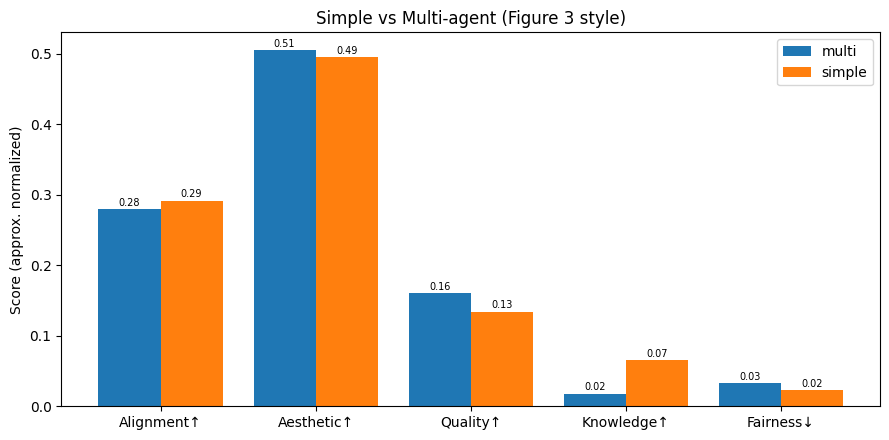

Normalization: aesthetic/10, quality = IS / n_images (upper bound), baaki raw. Paper ki exact normalization alag ho sakti hai.


In [10]:
fair_df = run_fairness(BENCH_MODEL, n_base=4)
display(fair_df.groupby(["strategy", "substituted"])["delta_S"].mean().unstack())
plot_figure3(summary, fair_df)

### 8c. Disaggregated analysis (Figure 4 / 6 / 7 style)

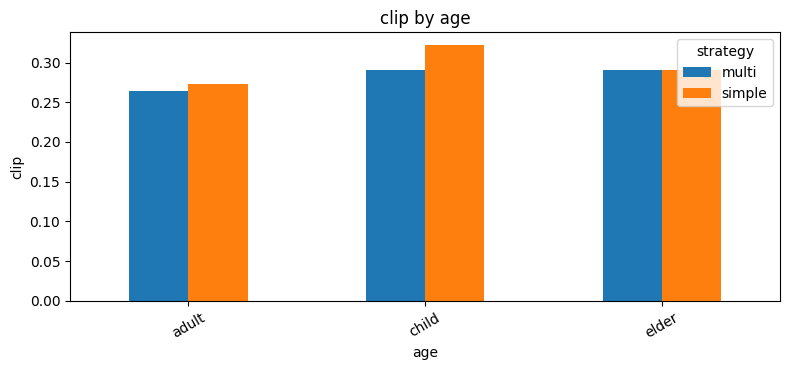

strategy,multi,simple
age,,
adult,0.263979,0.273318
child,0.290934,0.321977
elder,0.290671,0.290608


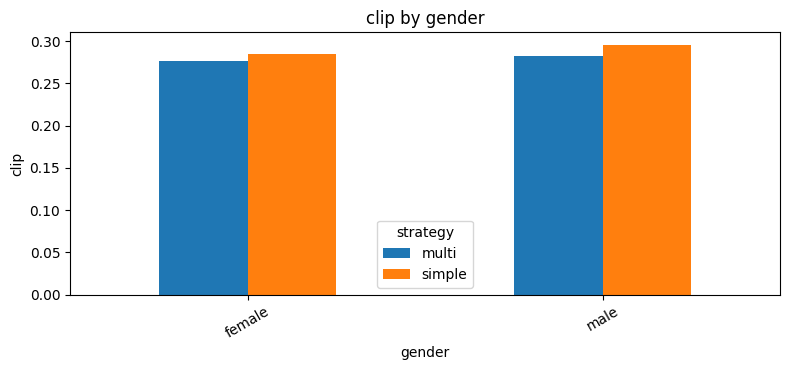

strategy,multi,simple
gender,,
female,0.276190,0.285089
male,0.282062,0.295644


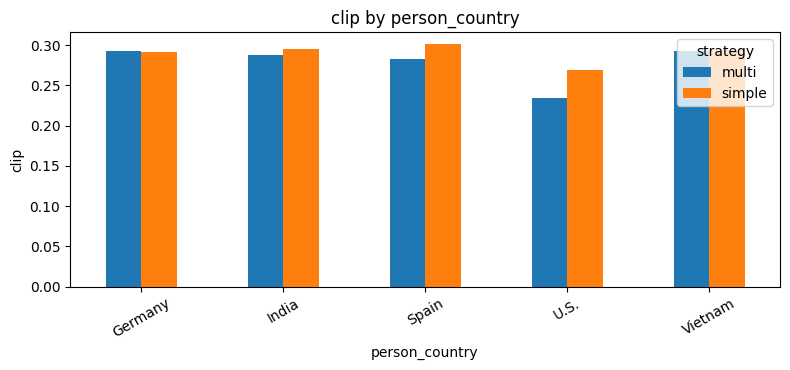

strategy,multi,simple
person_country,,
Germany,0.292238,0.291348
India,0.288458,0.294728
Spain,0.283268,0.300983
U.S.,0.234842,0.268801
Vietnam,0.293021,0.293763


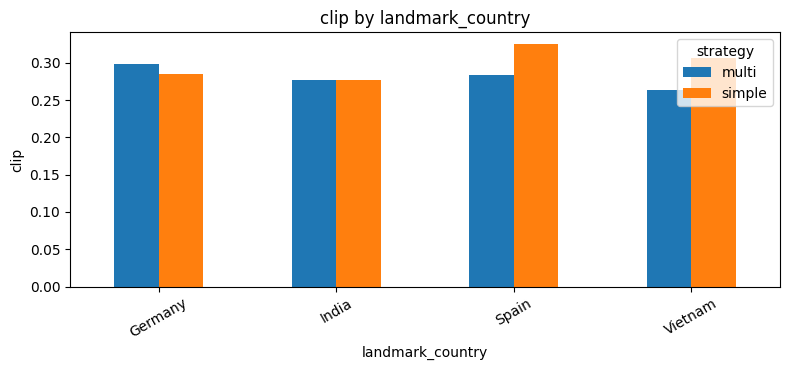

strategy,multi,simple
landmark_country,,
Germany,0.297793,0.285106
India,0.277554,0.277012
Spain,0.283833,0.324583
Vietnam,0.263400,0.306753


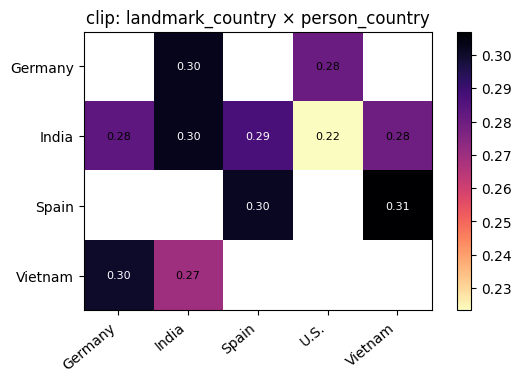

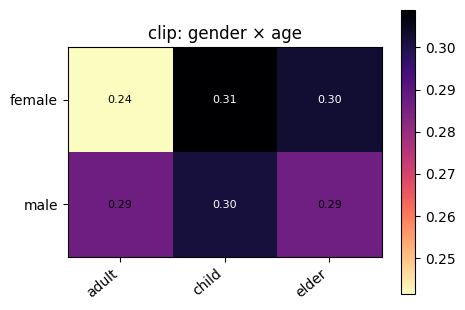

age,adult,child,elder
gender,,,
female,0.241364,0.308958,0.302555
male,0.286838,0.301452,0.286668


In [11]:
for by in ["age", "gender", "person_country", "landmark_country"]:
    display(plot_breakdown(bench_df, by, "clip"))
plot_heatmap(bench_df, "landmark_country", "person_country", "clip")
plot_heatmap(bench_df, "gender", "age", "clip")
# Multilingual (Figure 5/7): AltDiffusion par languages=tuple(LANGUAGES) ke saath run_benchmark chalao, phir:
# plot_breakdown(df_multi, "language", "clip"); plot_heatmap(df_multi, "language", "person_country", "clip")

### 8d. Progress dashboard (kabhi bhi chalao)

In [12]:
show_progress()

Storage: /content/drive/MyDrive/MosAIG_Studio
Cached captions: 54 | translations: 0
 - AltDiffusion-m18_fast_s42: images=24, scored=24, aesthetic=24
 - fairness_AltDiffusion-m18_fast_s42: images=32, scored=32, aesthetic=0
Studio runs: 2


## 9. Human evaluation + error analysis (paper Section 4.4, Appendix D)

Blinded 5-point Likert: **Alignment**, **Quality** (AI vs real), **Aesthetics**, plus error tags. Do raters ke liye alag `rater_id` se bharo, phir weighted Cohen's κ.
**Safety:** template agar pehle se bhara hua ho to ye cell use **overwrite nahi karta** (ratings bachti hain).

In [13]:
ALIGN_Q = "How well does the image match the description? 1 Does not match at all, 2 Significant discrepancies, 3 Several minor, 4 A few minor, 5 Matches exactly"
QUALITY_Q = "Is the image AI-generated or real? 1 AI-generated, 2 Probably AI but photorealistic, 3 Neutral, 4 Probably real but irregular textures, 5 Real photo"
AESTH_Q = "How aesthetically pleasing is the image? 1 Ugly ... 5 Stunning"
ERROR_TAGS = "background_error | landmark_error/omission | human_rendering_error | attire_or_stereotype_issue | body_distortion | multiplicity | none"

def create_human_eval_pack(df, n=60, seed=SEED, overwrite=False):
    tpl_path = HUMAN_DIR / "human_eval_template.csv"
    if tpl_path.exists() and not overwrite:
        print("Template pehle se maujood hai (ratings safe):", tpl_path, "\nNaya banana ho to overwrite=True do."); return
    d = df.sample(n=min(n, len(df)), random_state=seed).reset_index(drop=True)
    bdir = HUMAN_DIR / "blinded_images"; bdir.mkdir(parents=True, exist_ok=True)
    tpl, key = [], []
    for i, r in d.iterrows():
        sid = "S" + hashlib.sha256(f"{i}|{r['image_path']}|{seed}".encode()).hexdigest()[:10].upper()
        shutil.copy2(r["image_path"], bdir / f"{sid}.png")
        tpl.append(dict(sample_id=sid, blinded_image=str(bdir / f"{sid}.png"), prompt=r["caption_en"], nationality=r["nationality"], age=r["age"],
                        gender=r["gender"], landmark=r["landmark"], rater_id="", alignment_1to5="", quality_1to5="", aesthetics_1to5="", error_tags="", notes=""))
        key.append(dict(sample_id=sid, strategy=r["strategy"], language=r["language"], image_path=r["image_path"]))
    pd.DataFrame(tpl).sample(frac=1, random_state=seed).to_csv(tpl_path, index=False)
    pd.DataFrame(key).to_csv(HUMAN_DIR / "PRIVATE_blinding_key.csv", index=False)
    print("Questions:\n -", ALIGN_Q, "\n -", QUALITY_Q, "\n -", AESTH_Q, "\nError tags:", ERROR_TAGS)
    print("Template:", tpl_path, "| PRIVATE key (raters ko mat dikhao):", HUMAN_DIR / "PRIVATE_blinding_key.csv")

def analyze_human_ratings(completed_csv):
    from sklearn.metrics import cohen_kappa_score
    r = pd.read_csv(completed_csv); k = pd.read_csv(HUMAN_DIR / "PRIVATE_blinding_key.csv")
    r = r.merge(k[["sample_id", "strategy", "language"]], on="sample_id", how="left")
    cols = ["alignment_1to5", "quality_1to5", "aesthetics_1to5"]
    for c in cols: r[c] = pd.to_numeric(r[c], errors="coerce")
    display(r.groupby("strategy")[cols].agg(["mean", "std", "count"]).round(2))
    for c in cols:
        w = r.pivot_table(index="sample_id", columns="rater_id", values=c, aggfunc="mean"); rs = list(w.columns)
        if len(rs) >= 2:
            pair = w[[rs[0], rs[1]]].dropna()
            if len(pair) > 1: print(f"{c}: weighted Cohen's kappa ({rs[0]} vs {rs[1]}) =", round(cohen_kappa_score(pair[rs[0]].round(), pair[rs[1]].round(), weights="quadratic"), 3), f"(n={len(pair)})")
    if "error_tags" in r:
        tags = r["error_tags"].dropna().astype(str).str.split("|").explode().str.strip(); display(tags[tags != ""].value_counts().rename("error_count"))

create_human_eval_pack(bench_df, n=24)
# Ratings bharne ke baad: analyze_human_ratings(str(HUMAN_DIR / "human_eval_template_completed.csv"))

Template pehle se maujood hai (ratings safe): /content/drive/MyDrive/MosAIG_Studio/results/human_eval/human_eval_template.csv 
Naya banana ho to overwrite=True do.


## 10. 🚀 Premium Studio — real-world app

Prompt (English / हिन्दी / Deutsch / Español / Tiếng Việt) → fields parse → **MosAIG multi-agent caption** → **N candidates** → **CLIP + knowledge + aesthetics** se rank → **best image**. Har run `results/studio/<timestamp>/` mein (candidates, BEST.png, metadata.json) Drive par save hota hai; har candidate generate hote hi save hota hai.

In [14]:
NAT_KEYS = {"german": "German", "germany": "German", "indian": "Indian", "india": "Indian", "spanish": "Spanish", "spain": "Spanish", "spaniard": "Spanish",
            "american": "American", "u.s.": "American", "usa": "American", "vietnamese": "Vietnamese", "vietnam": "Vietnamese"}

def _keyword_parse(text):
    t = text.lower(); d = dict(nationality=None, age=None, gender=None, landmark=None, language="English", extra="")
    for k, v in NAT_KEYS.items():
        if re.search(r"\b" + re.escape(k) + r"\b", t): d["nationality"] = v; break
    for lm in sorted(LANDMARKS, key=len, reverse=True):
        if lm.lower() in t: d["landmark"] = lm; break
    if re.search(r"\b(girl|woman|female|lady|she|grandmother|mother)\b", t): d["gender"] = "female"
    elif re.search(r"\b(boy|man|male|gentleman|he|grandfather|father)\b", t): d["gender"] = "male"
    if re.search(r"\b(child|kid|boy|girl|toddler|teen)\b", t): d["age"] = "child"
    elif re.search(r"\b(old|elder|elderly|senior|grand\w+)\b", t): d["age"] = "elder"
    elif re.search(r"\b(adult|man|woman|young)\b", t): d["age"] = "adult"
    return d

def parse_user_prompt(text):
    d = _keyword_parse(text)
    if _LLM["client"] is not None:
        sysmsg = "You extract structured fields from an image request. Return ONLY a JSON object."
        usr = (f"Allowed nationality: {NATIONALITIES}. Allowed landmark: {LANDMARKS}. Allowed age: {AGES}. Allowed gender: {GENDERS}. "
               f"Language must be one of {LANGUAGES}.\nUse null if a field is absent or not in the allowed list.\nRequest: {text}\n"
               'JSON keys: nationality, age, gender, landmark, language, extra_details (short extra visual details to keep, or "").')
        raw = ask_llm(sysmsg, usr, 220, 0.0)
        try:
            j = json.loads(re.search(r"\{.*\}", raw, flags=re.S).group(0))
            for k, allowed in [("nationality", NATIONALITIES), ("age", AGES), ("gender", GENDERS), ("landmark", LANDMARKS), ("language", LANGUAGES)]:
                v = j.get(k)
                if isinstance(v, str):
                    m = [a for a in allowed if a.lower() == v.lower()]
                    if m: d[k] = m[0]
            d["extra"] = (j.get("extra_details") or "").strip() if isinstance(j.get("extra_details"), str) else ""
        except Exception:
            pass
    return d

def enhance_free_prompt(text, language):
    en = to_english(text, language)
    out = ask_llm("You rewrite image requests into rich, vivid text-to-image captions.",
                  f"Rewrite as ONE line under 48 words in English. Keep every detail the user gave; add only neutral photographic detail (lighting, composition); do not add stereotypes or new people.\nRequest: {en}\nOutput only the caption.", 140, 0.5)
    return (out or en).strip().split("\n")[0].strip('"')

def rank_candidates(images, caption_en, landmark, use_aesthetic=True):
    rows = []
    for i, im in enumerate(images):
        s = score_image(im, caption_en, landmark, salt="studio"); s["cand"] = i + 1; rows.append(s)
    df = pd.DataFrame(rows)
    df["aesthetic"] = score_aesthetic(images) if use_aesthetic else np.nan
    def mm(x):
        x = pd.to_numeric(x, errors="coerce").astype(float); lo, hi = np.nanmin(x), np.nanmax(x)
        return (x - lo) / (hi - lo) if np.isfinite(lo) and hi > lo else x * 0 + 0.5
    parts = {"clip": 0.45, "knowledge": 0.30, "aesthetic": 0.25}; tot = 0; score = np.zeros(len(df))
    for c, w in parts.items():
        if pd.to_numeric(df[c], errors="coerce").notna().any(): score += w * mm(df[c]).fillna(0.5).to_numpy(); tot += w
    df["final_score"] = score / max(tot, 1e-9)
    return df.sort_values("final_score", ascending=False).reset_index(drop=True)

def studio_generate(text, model, strategy, n_cand, preset, seed, use_aesthetic, native_lang, negative,
                    nationality="", age="", gender="", landmark="", language_override="", progress=None):
    t0 = time.time(); text = (text or "").strip(); log = []
    d = parse_user_prompt(text) if text else dict(nationality=None, age=None, gender=None, landmark=None, language="English", extra="")
    for k, v in [("nationality", nationality), ("age", age), ("gender", gender), ("landmark", landmark), ("language", language_override)]:
        if v: d[k] = v
    lang = d["language"] or "English"
    if not text and not (d["nationality"] and d["landmark"]): raise ValueError("Prompt likho ya nationality + landmark select karo.")
    structured = bool(d["nationality"] and d["landmark"])
    log.append(f"Parsed: {json.dumps(d, ensure_ascii=False)}")
    if strategy.startswith("Raw") or not structured:
        caption_en = enhance_free_prompt(text, lang) if (text and not strategy.startswith("Raw")) else to_english(text, lang)
        if not structured: log.append("Landmark/nationality nahi mila -> free-form rich caption mode (knowledge score off).")
        agent_log = []
    elif strategy.startswith("Simple"):
        caption_en = simple_caption(d["nationality"], d["age"] or "adult", d["gender"], d["landmark"]); agent_log = []
    else:
        if progress: progress(0.05, desc="Multi-agent conversation...")
        caption_en, agent_log = mosaig_caption(d["nationality"], d["age"] or "adult", d["gender"], d["landmark"], extra=d.get("extra", ""))
    use_native = native_lang and MODELS[model]["multilingual"] and lang != "English"
    caption_used = translate_text(caption_en, lang) if use_native else caption_en
    lm = d["landmark"] if structured else None
    stamp = time.strftime("%Y%m%d_%H%M%S"); folder = STUDIO_DIR / stamp; folder.mkdir(parents=True, exist_ok=True)
    imgs = []
    for i in range(int(n_cand)):
        if progress: progress(0.1 + 0.6 * i / max(1, int(n_cand)), desc=f"Generating candidate {i+1}/{int(n_cand)}")
        im = generate_image(model, caption_used, preset, seed=int(seed) + i, negative=negative)
        _atomic_save_image(im, folder / f"cand_{i+1}.png"); imgs.append(im)
    unload_pipeline()
    if progress: progress(0.8, desc="Ranking candidates (CLIP + knowledge + aesthetics)...")
    table = rank_candidates(imgs, caption_en, lm, use_aesthetic); unload_evaluators()
    best = imgs[int(table.loc[0, "cand"]) - 1]; _atomic_save_image(best, folder / "BEST.png")
    gallery = [(imgs[int(r["cand"]) - 1], f"#{int(r['cand'])} score {r['final_score']:.2f} | clip {r['clip']:.3f}") for _, r in table.iterrows()]
    meta = dict(prompt=text, parsed=d, strategy=strategy, model=model, preset=preset, caption_en=caption_en, caption_used=caption_used,
                seed=int(seed), candidates=int(n_cand), scores=table.round(4).to_dict("records"), agent_log=agent_log, seconds=round(time.time() - t0, 1))
    _atomic_write_text(folder / "metadata.json", json.dumps(meta, ensure_ascii=False, indent=2, default=str))
    log.append(f"Saved: {folder}")
    agent_text = "\n".join(f"[{a}] {t}" for a, t in agent_log) or "(agents not used)"
    cap_text = f"English caption:\n{caption_en}" + (f"\n\nCaption used by model ({lang}):\n{caption_used}" if use_native else "")
    return best, gallery, cap_text, table.round(3), agent_text + "\n\n" + "\n".join(log)
print("Studio engine ready.")

Studio engine ready.


In [15]:
import gradio as gr

def ui_free(text, model, strategy, n, preset, seed, aes, native, neg, progress=gr.Progress()):
    try: return studio_generate(text, model, strategy, n, preset, seed, aes, native, neg, progress=progress)
    except Exception as e: raise gr.Error(f"{type(e).__name__}: {str(e)[:700]}")

def ui_struct(nat, age, gen, lm, lang, model, strategy, n, preset, seed, aes, native, neg, progress=gr.Progress()):
    try: return studio_generate("", model, strategy, n, preset, seed, aes, native, neg, nat, age, gen, lm, lang, progress=progress)
    except Exception as e: raise gr.Error(f"{type(e).__name__}: {str(e)[:700]}")

def ui_compare(nat, age, gen, lm, model, preset, seed, progress=gr.Progress()):
    try:
        res = {}
        for k, strat in enumerate(["Simple caption", "Multi-agent MosAIG"]):
            progress(0.1 + 0.4 * k, desc=f"{strat}...")
            res[strat] = studio_generate("", model, strat, 1, preset, seed, False, False, NEGATIVE_PROMPT, nat, age, gen, lm, "English")
        a, b = res["Simple caption"], res["Multi-agent MosAIG"]
        return a[0], a[2] + f"\n\nclip={a[3].loc[0,'clip']:.3f}", b[0], b[2] + f"\n\nclip={b[3].loc[0,'clip']:.3f}"
    except Exception as e: raise gr.Error(f"{type(e).__name__}: {str(e)[:700]}")

MODEL_CHOICES = list(MODELS); STRATS = ["Multi-agent MosAIG", "Simple caption", "Raw prompt (no rewriting)"]
css = ".gradio-container{max-width:1300px!important} #hero{padding:16px;border-radius:14px;border:1px solid var(--border-color-primary)}"
with gr.Blocks(theme=gr.themes.Soft(), css=css, title="MosAIG Studio") as demo:
    gr.Markdown('<div id="hero"><h1>🌏 MosAIG Studio</h1><p>Multicultural text-to-image: prompt likho, app multi-agent caption banakar kai candidates generate karta hai aur <b>best image</b> chunta hai.</p><p><i>Research prototype: scores proxies hain; culture/landmark accuracy khud check karo.</i></p></div>')
    with gr.Tab("✨ Prompt → Best Image"):
        with gr.Row():
            with gr.Column(scale=5):
                p = gr.Textbox(label="Prompt (English / हिन्दी / Deutsch / Español / Tiếng Việt)", lines=4,
                               placeholder="e.g. A Vietnamese grandmother visiting the Taj Mahal at sunrise")
                with gr.Row():
                    m = gr.Dropdown(MODEL_CHOICES, value="AltDiffusion-m18", label="Image model")
                    s = gr.Dropdown(STRATS, value=STRATS[0], label="Caption strategy")
                with gr.Row():
                    n = gr.Slider(1, 6, value=3, step=1, label="Candidates (best-of-N)")
                    pr = gr.Radio(["fast", "paper"], value="fast", label="Preset (paper = slow)")
                    sd = gr.Number(value=42, precision=0, label="Seed")
                with gr.Row():
                    aes = gr.Checkbox(value=True, label="Use aesthetics in ranking (slower)")
                    nat = gr.Checkbox(value=True, label="AltDiffusion: use my language directly")
                neg = gr.Textbox(value=NEGATIVE_PROMPT, label="Negative prompt", lines=2)
                b = gr.Button("Generate best image", variant="primary")
            with gr.Column(scale=5):
                best = gr.Image(label="🏆 Best image", type="pil")
        gal = gr.Gallery(label="All candidates (ranked)", columns=3, height=300)
        with gr.Row():
            cap = gr.Textbox(label="Caption(s)", lines=6); tab = gr.Dataframe(label="Scores")
        alog = gr.Textbox(label="Agent conversation + log", lines=10)
        b.click(ui_free, [p, m, s, n, pr, sd, aes, nat, neg], [best, gal, cap, tab, alog])
    with gr.Tab("🧩 Structured (paper mode)"):
        with gr.Row():
            sn = gr.Dropdown(NATIONALITIES, value="Vietnamese", label="Person nationality"); sa = gr.Dropdown(AGES, value="child", label="Age")
            sg = gr.Dropdown(GENDERS, value="female", label="Gender"); sl = gr.Dropdown(LANDMARKS, value="Golden Gate Bridge", label="Landmark")
            sla = gr.Dropdown(LANGUAGES, value="English", label="Caption language")
        with gr.Row():
            sm = gr.Dropdown(MODEL_CHOICES, value="AltDiffusion-m18", label="Model"); ss = gr.Dropdown(STRATS, value=STRATS[0], label="Strategy")
            sn2 = gr.Slider(1, 6, value=3, step=1, label="Candidates"); spr = gr.Radio(["fast", "paper"], value="fast", label="Preset"); ssd = gr.Number(value=42, precision=0, label="Seed")
        with gr.Row():
            saes = gr.Checkbox(value=True, label="Aesthetics in ranking"); snat = gr.Checkbox(value=True, label="Use native language (Alt)")
        sneg = gr.Textbox(value=NEGATIVE_PROMPT, label="Negative prompt", lines=1); sb = gr.Button("Generate", variant="primary")
        sbest = gr.Image(label="🏆 Best", type="pil"); sgal = gr.Gallery(label="Candidates", columns=3, height=260)
        scap = gr.Textbox(label="Caption(s)", lines=5); stab = gr.Dataframe(label="Scores"); slog = gr.Textbox(label="Agent log", lines=9)
        sb.click(ui_struct, [sn, sa, sg, sl, sla, sm, ss, sn2, spr, ssd, saes, snat, sneg], [sbest, sgal, scap, stab, slog])
    with gr.Tab("⚖️ Simple vs MosAIG"):
        with gr.Row():
            cn = gr.Dropdown(NATIONALITIES, value="Vietnamese", label="Nationality"); ca = gr.Dropdown(AGES, value="child", label="Age")
            cg = gr.Dropdown(GENDERS, value="female", label="Gender"); cl = gr.Dropdown(LANDMARKS, value="Golden Gate Bridge", label="Landmark")
        with gr.Row():
            cm = gr.Dropdown(MODEL_CHOICES, value="AltDiffusion-m18", label="Model"); cpr = gr.Radio(["fast", "paper"], value="fast", label="Preset"); csd = gr.Number(value=42, precision=0, label="Seed")
        cb = gr.Button("Compare (same seed)", variant="primary")
        with gr.Row():
            ci1 = gr.Image(label="Simple", type="pil"); ci2 = gr.Image(label="Multi-agent (MosAIG)", type="pil")
        with gr.Row():
            ct1 = gr.Textbox(label="Simple caption", lines=4); ct2 = gr.Textbox(label="MosAIG caption", lines=4)
        cb.click(ui_compare, [cn, ca, cg, cl, cm, cpr, csd], [ci1, ct1, ci2, ct2])
    with gr.Tab("ℹ️ About & limits"):
        gr.Markdown("""**Based on:** *When Cultures Meet* (ACL Findings 2026). **Limits:** CLIP/aesthetic scores are proxies; images can show wrong landmarks or stereotyped attire. Review outputs before use. Demographics are limited to 5 countries, 3 age groups, 2 genders (as in the paper). If Colab shows a public Gradio link, anyone with the link can use the app while it runs; do not upload private data. FLUX.1 Lite needs a large GPU.""")







demo.queue(max_size=2, default_concurrency_limit=1)

demo.launch(
    share=True,
    debug=False,
    server_name="0.0.0.0",
    prevent_thread_lock=True
)









Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5892933bdb7327f993.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:
!pip install --force-reinstall --no-cache-dir "pydantic==2.11.7"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.0 MB/s  0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: annotated-types
    Found existing installation: annotated-types 0.8.0
    Uninstalling annotated-types-0.8.0:
      Successfully uninstalled annotated-types-0.8.0
  Attempting uninstall: typing-inspection
    Found existing installation: typing-inspection 0.4.4
    Uninstalling typing-inspection-0.4.4:
      Successfully uninstalled typing-inspection-0.4.4
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.33.2
    Uninstalling pydantic_core-2.33.2:
      Successfully uninstalled pydantic_core-2.33.2
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.11.7
    Uninstalling pydantic-2.11.7:
      Successfully uninstalled pydantic-2.11

## 11. Export (results ZIP)

In [17]:
def export_bundle():
    zp = PROJECT_DIR / "MosAIG_Studio_Results.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for p in RESULTS_DIR.rglob("*"):
            if p.is_file() and p.name != "PRIVATE_blinding_key.csv" and ".tmp" not in p.name: z.write(p, p.relative_to(PROJECT_DIR))
        if CACHE_FILE.exists(): z.write(CACHE_FILE, CACHE_FILE.name)
    print("ZIP:", zp, round(zp.stat().st_size / 1024**2, 1), "MB")
    return zp
zip_path = export_bundle()
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as e:
    print("Download manually from the Files panel:", zip_path)

ZIP: /content/drive/MyDrive/MosAIG_Studio/MosAIG_Studio_Results.zip 36.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Troubleshooting

| Problem | Fix |
|---|---|
| GPU quota khatam / disconnect | Naya GPU runtime → Cell 1 + Restart → Cell 2..7 → adhoora cell dobara run. Sab kuch Drive se resume hota hai |
| `GPU available nahi hai` | Runtime type T4 GPU karo; bina GPU ke generation intentionally block hai |
| `Groq call fail hui` | Rate limit; thodi der baad same cell dobara run (bacha hua hi chalega) |
| `Storage: ... LOCAL` message | Drive mount nahi hua; Cell 2 dobara chalao aur permission do, warna disconnect par sab delete |
| `No module named groq` / `FqnToConfig` | Cell 1 chalao + restart |
| RAM crash | Ek model, kam candidates, preset `fast`, session restart |
| FLUX blocked | ≥24GB VRAM / 25GB RAM chahiye; T4 par AltDiffusion/SDXL |
| `n_cases` badhana hai | Sirf number badhao; purane images/scores reuse hote hain |
| Naya run bilkul shuru se | `tag="naya_naam"` do, ya Drive mein `MosAIG_Studio/results/benchmark/<tag>` folder delete karo |

**Citation:** Bhalerao, Yalamarty, Trinh, Ignat. *When Cultures Meet: Multicultural Text-to-Image Generation.* Findings of ACL 2026. Code/dataset: github.com/AIM-SCU/MosAIG